In [1]:
!pip install optuna
!pip install MLstatkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 2.2 MB/s eta 0:00:00


In [2]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score, brier_score_loss, roc_curve, accuracy_score, recall_score, confusion_matrix, f1_score, classification_report
from sklearn.utils import resample
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder
import shap
import optuna
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.metrics import AUC
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop
from tensorflow.keras.callbacks import EarlyStopping

# 1. Import dataset mejorado

Nueva variable objetivo -> **'ASIA Score at 1-year'**

Tratamiento del dataset:
- Quitar pacientes con ASIA Score at 1-year nulo. **OJO!** Reducción del dataset a un 35% del original
- Estudiar balanceo de clases
- Separación train (80%) - test (20%), random_state=52 (igual que en el resto de cuadernillos)

In [3]:
df = pd.read_csv('/content/drive/MyDrive/TFG Paula Hernández - colab/dataset-modificado.csv')
df_imputed = pd.read_csv('/content/drive/MyDrive/TFG Paula Hernández - colab/dataset-modificado-imputed.csv')

In [4]:
df = df.drop(columns= ["Walk One Block at 1-year",
    "Walk Flight of Stairs at 1-year",
    'Walk 150 ft at 1-year'])

df_imputed = df_imputed.drop(columns= ["Walk One Block at 1-year",
    "Walk Flight of Stairs at 1-year",
    'Walk 150 ft at 1-year'])

previous_n = len(df)

In [5]:
var_obj = 'ASIA Score at 1-year'

**Quitar pacientes con ASIA Score at 1-year nulo.**

In [6]:
df = df[df[var_obj].notna()]
df_imputed = df_imputed[df_imputed[var_obj] != -1]

n = len(df)

In [7]:
len(df_imputed)

1449

In [8]:
print(f'El dataset ha pasado de {previous_n} pacientes a {n}.\nEsto es una reducción del {((1 - n/previous_n) * 100):.2f}% respecto al original')

El dataset ha pasado de 4057 pacientes a 1449.
Esto es una reducción del 64.28% respecto al original


**Separación train/test**

Como ahora tenemos clases desbalanceadas, utilizaremos el parámetro *stratify* para que los conjuntos de entrenamiento y test tengan la misma proporción de cada clase.

In [9]:
df_x = df.drop(columns=var_obj)
df_y = df[var_obj]

df_x_imputed = df_imputed.drop(columns=var_obj)
df_y_imputed = df_imputed[var_obj]

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    df_x, df_y, test_size=0.2, random_state=52, stratify=df_y)

X_train_imputed, X_test_imputed, y_train_imputed, y_test_imputed = train_test_split(
    df_x_imputed, df_y_imputed, test_size=0.2, random_state=52, stratify=df_y_imputed)

**Balanceo de clases**
Oversampling en la clase 5 y el resto de balanceo intentar contrarestarlo en los modelos, no en los datos?

Recordatorio:
A = 1, B = 2, C = 3, D = 4, E = 5


In [11]:
y_train.value_counts()

,count
ASIA Score at 1-year,
4.0,475
1.0,382
3.0,159
2.0,130
5.0,13


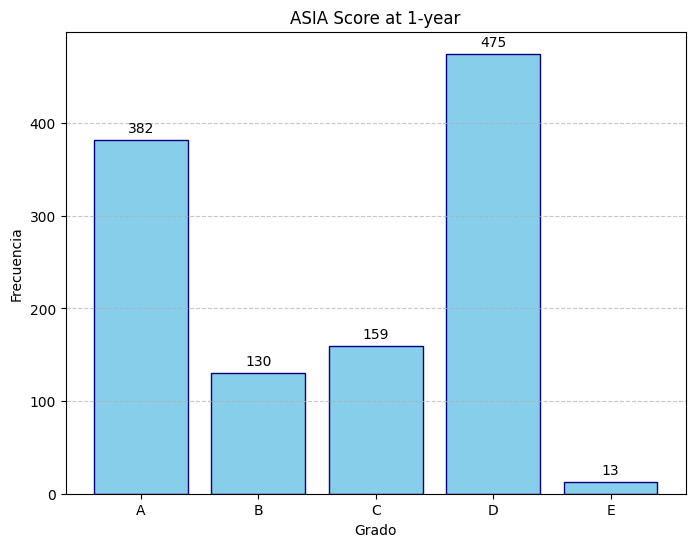

In [12]:
# GRÁFICO DESBALANCEO

counts = {1.0: 382, 2.0: 130, 3.0: 159, 4.0: 475, 5.0: 13}
mapping = {1.0: 'A', 2.0: 'B', 3.0: 'C', 4.0: 'D', 5.0: 'E'}

labels = [mapping[k] for k in sorted(counts.keys())]
values = [counts[k] for k in sorted(counts.keys())]

plt.figure(figsize=(8, 6))
bars = plt.bar(labels, values, color='skyblue', edgecolor='navy')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, int(yval), ha='center', va='bottom')

plt.title('ASIA Score at 1-year')
plt.xlabel('Grado')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

In [14]:
# Oversampling clase 5

from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(sampling_strategy={5: 100}, random_state=42)
X_train_over, y_train_over = ros.fit_resample(X_train, y_train)

ros_imputed = RandomOverSampler(sampling_strategy={5: 100}, random_state=42)
X_train_over_imputed, y_train_over_imputed = ros.fit_resample(X_train_imputed, y_train_imputed)

In [15]:
y_train_over.value_counts()

,count
ASIA Score at 1-year,
4.0,475
1.0,382
3.0,159
2.0,130
5.0,100


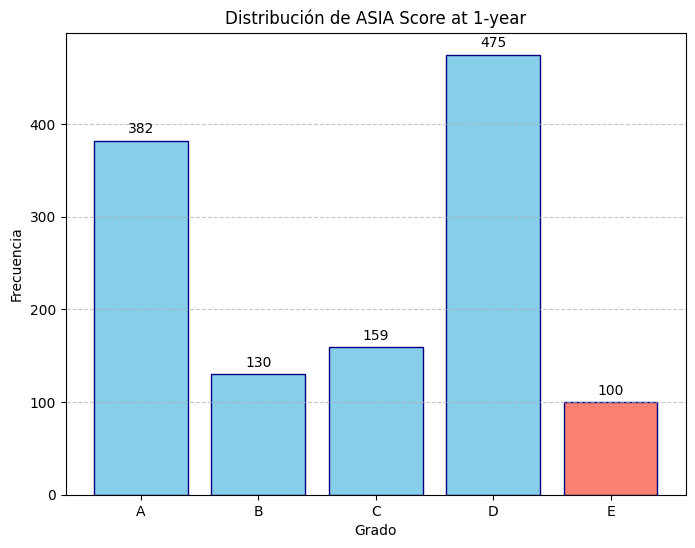

In [13]:

labels = ['A', 'B', 'C', 'D', 'E']
values = [382, 130, 159, 475, 100]

# Definimos una lista de colores: skyblue para casi todas, salmón para la E
colors = ['skyblue', 'skyblue', 'skyblue', 'skyblue', 'salmon']

plt.figure(figsize=(8, 6))
bars = plt.bar(labels, values, color=colors, edgecolor='navy')

# Añadir etiquetas sobre las barras
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, int(yval), ha='center', va='bottom')

plt.title('Distribución de ASIA Score at 1-year')
plt.xlabel('Grado')
plt.ylabel('Frecuencia')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

# 2. Modelos de clasificación

## 2.1 Regresión logística ElasticNet

In [ ]:
def objective(trial):
    l1_ratio = trial.suggest_float('l1_ratio', 0.0, 1.0)
    C = trial.suggest_float('C', 0.0001, 100, log=True)

    model = LogisticRegression(
        penalty='elasticnet',
        solver='saga',
        l1_ratio=l1_ratio,
        C=C,
        max_iter=5000,
        class_weight='balanced',
        random_state=42
    )

    model.fit(X_train_over_imputed, y_train_over_imputed)

    y_proba = model.predict_proba(X_test_imputed)

    return roc_auc_score(
        y_test_imputed,
        y_proba,
        multi_class='ovr', # más estable y simple
        average='macro' # no tiene en cuenta desbalanceo
    )

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=10, show_progress_bar=True)


print('Mejores hiperparámetros:', study.best_params)
print('Mejor ROC AUC:', study.best_value)


[I 2026-03-31 18:18:05,402] A new study created in memory with name: no-name-c4fe0cf8-c643-4b61-9039-e2f563c1c049


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-03-31 18:19:04,586] Trial 0 finished with value: 0.8942116530636101 and parameters: {'l1_ratio': 0.7348355374647737, 'C': 0.0746624826072727}. Best is trial 0 with value: 0.8942116530636101.


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[I 2026-03-31 18:19:42,608] Trial 1 finished with value: 0.8659834106159996 and parameters: {'l1_ratio': 0.04287052540100866, 'C': 0.9732383248830787}. Best is trial 0 with value: 0.8942116530636101.


...

[I 2026-03-31 18:20:24,420] Trial 2 finished with value: 0.8652764891277487 and parameters: {'l1_ratio': 0.6955569548998699, 'C': 21.50572927898441}. Best is trial 0 with value: 0.8942116530636101.


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[I 2026-03-31 18:21:03,636] Trial 3 finished with value: 0.8653314527655652 and parameters: {'l1_ratio': 0.2873502185046771, 'C': 30.95846320173299}. Best is trial 0 with value: 0.8942116530636101.
[I 2026-03-31 18:21:33,876] Trial 4 finished with value: 0.881265380456967 and parameters: {'l1_ratio': 0.525217421408686, 'C': 0.20571980087078887}. Best is trial 0 with value: 0.8942116530636101.
[I 2026-03-31 18:21:53,957] Trial 5 finished with value: 0.5169508865968248 and parameters: {'l1_ratio': 0.6030832184915571, 'C': 0.00033902009463062635}. Best is trial 0 with value: 0.8942116530636101.
[I 2026-03-31 18:21:58,153] Trial 6 finished with value: 0.8779022785568209 and parameters: {'l1_ratio': 0.09679167658735433, 'C': 0.0038976010796077623}. Best is trial 0 with value: 0.8942116530636101.
[I 2026-03-31 18:22:25,056] Trial 7 finished with value: 0.8925042841348537 and parameters: {'l1_ratio': 0.9556110720727033, 'C': 0.058194709914851976}. Best is trial 0 with value: 0.894211653063610

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[I 2026-03-31 18:23:20,554] Trial 9 finished with value: 0.8653268849449649 and parameters: {'l1_ratio': 0.4169547383429203, 'C': 19.404183483946955}. Best is trial 0 with value: 0.8942116530636101.
Mejores hiperparámetros: {'l1_ratio': 0.7348355374647737, 'C': 0.0746624826072727}
Mejor ROC AUC: 0.8942116530636101


In [ ]:
# modelo final
best_model = LogisticRegression(
        penalty='elasticnet',
        solver='saga',
        l1_ratio=0.7348355374647737,
        C=0.0746624826072727,
        max_iter=5000,
        class_weight='balanced',
        random_state=42
    )
best_model.fit(X_train_over_imputed, y_train_over_imputed)


y_proba_elastic = best_model.predict_proba(X_test_imputed)
y_pred_elastic = best_model.predict(X_test_imputed)

In [ ]:
print("=" * 60)
print("MÉTRICAS")
print("=" * 60)

# C-statistic (AUC-ROC)
roc_auc = roc_auc_score(y_test_imputed, y_proba_elastic, multi_class='ovr', average='macro')
print(f"ROC_AUC:           {roc_auc:.3f}")

# Accuracy
accuracy = accuracy_score(y_test_imputed,y_pred_elastic)
print(f"Accuracy Score:    {accuracy:.3f}")

# Recall
recall = recall_score(y_test_imputed, y_pred_elastic, average='macro')
print(f"Recall:            {recall:.3f}")

# F1
f1 = f1_score(y_test_imputed, y_pred_elastic, average='macro')
print(f"F1 Score:          {f1:.3f}")

print("\nClassification Report")
print("-" * 60)
print(classification_report(y_test_imputed, y_pred_elastic))

MÉTRICAS
ROC_AUC:           0.894
Accuracy Score:    0.628
Recall:            0.557
F1 Score:          0.459

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

         1.0       0.75      0.89      0.81        96
         2.0       0.21      0.19      0.20        32
         3.0       0.41      0.45      0.43        40
         4.0       0.96      0.60      0.74       119
         5.0       0.07      0.67      0.12         3

    accuracy                           0.63       290
   macro avg       0.48      0.56      0.46       290
weighted avg       0.72      0.63      0.65       290



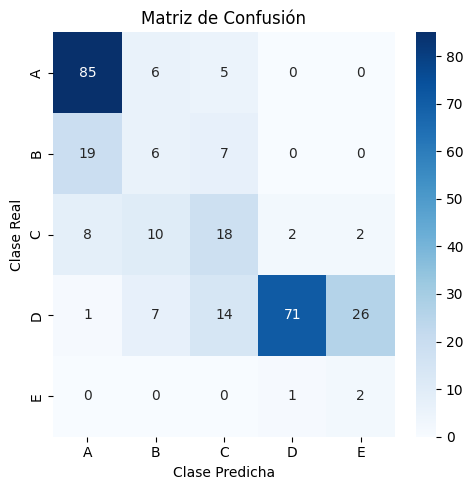

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test_imputed, y_pred_elastic)

# Visualizar
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['A', 'B', 'C', 'D', 'E'],
            yticklabels=['A', 'B', 'C', 'D', 'E'])

plt.title('Matriz de Confusión')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

### Explicabilidad



#### Explicabilidad global

In [ ]:
coef_df = pd.DataFrame({
    'feature': X_train_imputed.columns,
    'coef': np.mean(np.abs(best_model.coef_), axis=0) # media en valor absoluto de los 5 elasticnet (uno por clase)
}).sort_values(by='coef', key=abs, ascending=False)


In [ ]:
coef_df[abs(coef_df.coef) > 0]

,feature,coef
9,ASIA at Rehab,0.243534
10,Neuro Impairment,0.171378
63,Sensory PP Right L5,0.141569
26,Motor Score Left S1,0.140560
8,Deep Anal Pressure,0.097367
...,...,...
11,Anxiety,0.003085
51,Sensory PP Left L2,0.002620
65,Sensory PP Right S2,0.002386
43,Sensory LT Right L3,0.002352


#### Explicabilidad local (por clase)

In [ ]:
for i, coef in enumerate(best_model.coef_):
    print(f"\nClase {i+1}:")

    coef_df = pd.DataFrame({
        'feature': X_train_imputed.columns,
        'coef': coef
    })

    coef_df = coef_df.sort_values(by='coef', key=abs, ascending=False)

    print(coef_df.head())


Clase 1:
                feature      coef
9         ASIA at Rehab -0.755180
8    Deep Anal Pressure -0.486837
10     Neuro Impairment  0.289677
33   Sensory LT Left L2 -0.181975
42  Sensory LT Right L2 -0.178630

Clase 2:
                       feature      coef
26         Motor Score Left S1 -0.251351
66         Sensory PP Right S3 -0.201230
10            Neuro Impairment  0.152187
0                     Hispanic  0.144851
7   Voluntary Anal Contraction -0.102297

Clase 3:
                                 feature      coef
24                   Motor Score Left L4 -0.285422
42                   Sensory LT Right L2  0.222495
29                  Motor Score Right L4 -0.207129
81  Marital Status_Single, Never Married  0.153826
60                   Sensory PP Right L2  0.104544

Clase 4:
                 feature      coef
9          ASIA at Rehab  0.379132
26   Motor Score Left S1  0.315732
41   Sensory LT Right L1  0.220155
10      Neuro Impairment -0.191694
28  Motor Score Right L3  0.1

## 2.2 XGBoost

In [ ]:
# las etiquetas deben empezar en 0, no en 1

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y_train_enc = le.fit_transform(y_train_over)

In [ ]:
def objective(trial):

    params = {
        'objective': 'multi:softprob',
        'num_class': 5,
        'eval_metric': 'mlogloss',
        'learning_rate': trial.suggest_float('learning_rate', 0.001, 1, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 25),
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'subsample': trial.suggest_float('subsample', 0.25, 1.0),
        'random_state': 42
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    aucs = []

    for train_idx, val_idx in cv.split(X_train_over, y_train_enc):

        X_tr = X_train_over.iloc[train_idx]
        X_val = X_train_over.iloc[val_idx]
        y_tr = y_train_enc[train_idx]
        y_val = y_train_enc[val_idx]

        model = xgb.XGBClassifier(**params)
        model.fit(X_tr, y_tr)

        y_val_proba = model.predict_proba(X_val)

        auc = roc_auc_score(
            y_val,
            y_val_proba,
            multi_class='ovr',
            average='macro'
        )

        aucs.append(auc)

    return np.mean(aucs)


study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, show_progress_bar=True)


best_model = xgb.XGBClassifier(**study.best_params)
best_model.fit(X_train_over, y_train_enc)

[I 2026-04-02 12:26:19,714] A new study created in memory with name: no-name-622f3ea0-5a62-415d-adbc-6c30f6a9c833


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-04-02 12:26:20,879] Trial 0 finished with value: 0.870395155636718 and parameters: {'learning_rate': 0.9871238781257154, 'min_child_weight': 23, 'max_depth': 2, 'subsample': 0.8333577068518003}. Best is trial 0 with value: 0.870395155636718.
[I 2026-04-02 12:26:22,744] Trial 1 finished with value: 0.8857755773503178 and parameters: {'learning_rate': 0.004585599496415862, 'min_child_weight': 15, 'max_depth': 8, 'subsample': 0.7836050041910985}. Best is trial 1 with value: 0.8857755773503178.
[I 2026-04-02 12:26:24,280] Trial 2 finished with value: 0.8917037247301396 and parameters: {'learning_rate': 0.07513855538882688, 'min_child_weight': 21, 'max_depth': 5, 'subsample': 0.6840400271936361}. Best is trial 2 with value: 0.8917037247301396.
[I 2026-04-02 12:26:29,741] Trial 3 finished with value: 0.8944241292220771 and parameters: {'learning_rate': 0.01465145287462488, 'min_child_weight': 12, 'max_depth': 6, 'subsample': 0.8787618621962978}. Best is trial 3 with value: 0.89442412

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.04322682973627759, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=4, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:

y_pred_xgb = best_model.predict(X_test)
y_pred_xgb = le.inverse_transform(y_pred_xgb)

y_proba_xgb = best_model.predict_proba(X_test)

print("=" * 60)
print("MÉTRICAS")
print("=" * 60)

# C-statistic (AUC-ROC)
roc_auc = roc_auc_score(y_test.values, y_proba_xgb, multi_class='ovr', average='macro')
print(f"ROC_AUC:           {roc_auc:.3f}")

# Accuracy
accuracy = accuracy_score(y_test.values,y_pred_xgb)
print(f"Accuracy Score:    {accuracy:.3f}")

# Recall
recall = recall_score(y_test.values, y_pred_xgb, average='macro')
print(f"Recall:            {recall:.3f}")

# F1
f1 = f1_score(y_test.values, y_pred_xgb, average='macro')
print(f"F1 Score:          {f1:.3f}")

print("\nClassification Report")
print("-" * 60)
print(classification_report(y_test.values, y_pred_xgb))


MÉTRICAS
ROC_AUC:           0.891
Accuracy Score:    0.766
Recall:            0.542
F1 Score:          0.573

Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

         1.0       0.73      0.92      0.81        96
         2.0       0.27      0.12      0.17        32
         3.0       0.58      0.38      0.45        40
         4.0       0.90      0.96      0.93       119
         5.0       1.00      0.33      0.50         3

    accuracy                           0.77       290
   macro avg       0.69      0.54      0.57       290
weighted avg       0.73      0.77      0.74       290



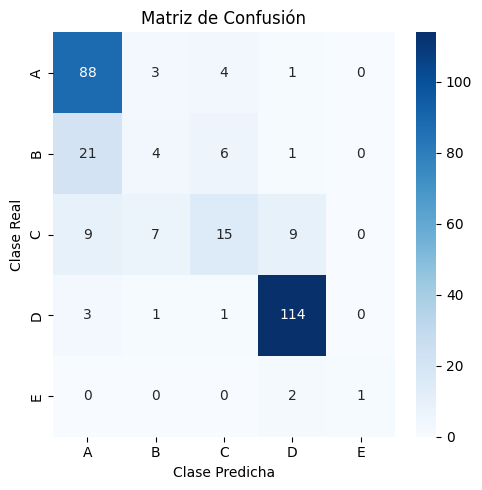

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_xgb)

# Visualizar
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['A', 'B', 'C', 'D', 'E'],
            yticklabels=['A', 'B', 'C', 'D', 'E'])

plt.title('Matriz de Confusión')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()

### Explicabilidad

In [ ]:
# Explainer específico para árboles
explainer = shap.TreeExplainer(best_model)

# shap_values: (n_samples, n_features)
shap_values = explainer.shap_values(X_test)


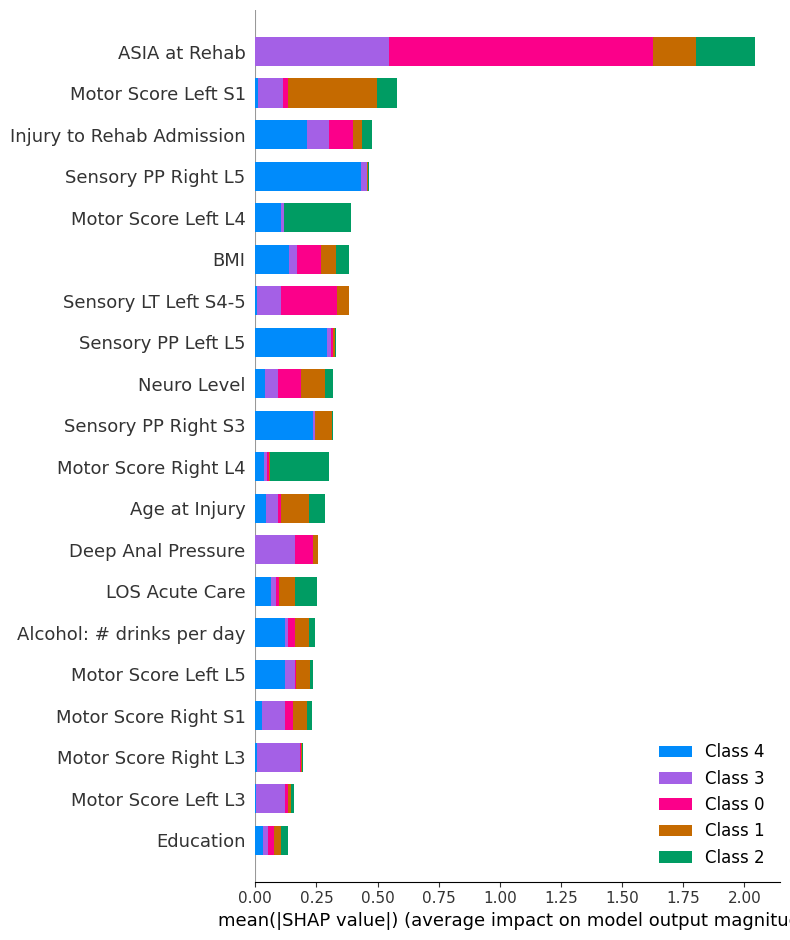

In [ ]:
shap.summary_plot(shap_values, X_test, plot_type="bar")

## 2.3 ANN

In [ ]:

# las etiquetas deben empezar en 0, no en 1
le = LabelEncoder()

y_train_enc_imputed_numpy = le.fit_transform(y_train_over_imputed)
y_test_enc_imputed_numpy = le.transform(y_test_imputed)

X_train_over_imputed_numpy = X_train_over_imputed.to_numpy(dtype='float32')
X_test_imputed_numpy = X_test_imputed.to_numpy(dtype='float32')

n_features = X_train_over_imputed_numpy.shape[1]
n_classes = 5

def objective(trial):

    hidden_nodes = trial.suggest_categorical("hidden_nodes", [8, 16, 32, 64, 128, 256])
    dropout_rate = trial.suggest_float("dropout_rate", 0.1, 0.4)
    optimizer_name = trial.suggest_categorical("optimizer", ["adam", "rmsprop"])
    learning_rate = trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True)

    inputs = Input(shape=(n_features,))
    x = Dense(hidden_nodes, activation='relu')(inputs)
    x = Dropout(dropout_rate)(x)
    outputs = Dense(n_classes, activation='softmax')(x)

    model = Model(inputs=inputs, outputs=outputs)

    if optimizer_name == "adam":
        optimizer = Adam(learning_rate=learning_rate)
    else:
        optimizer = RMSprop(learning_rate=learning_rate)

    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    )

    history = model.fit(
        X_train_over_imputed_numpy, y_train_enc_imputed_numpy,
        epochs=20,
        batch_size=32,
        validation_split=0.2,
        verbose=0,
        callbacks=[early_stop]
    )

    return history.history['val_accuracy'][-1]

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=15)

print("Best params:", study.best_trial.params)
print("Best accuracy:", study.best_value)

[I 2026-04-05 16:36:46,164] A new study created in memory with name: no-name-3e10e777-b340-4487-a356-1a2d3024849b
[I 2026-04-05 16:36:52,106] Trial 0 finished with value: 0.46799999475479126 and parameters: {'hidden_nodes': 128, 'dropout_rate': 0.2712008806979246, 'optimizer': 'rmsprop', 'learning_rate': 0.002476151983736651}. Best is trial 0 with value: 0.46799999475479126.
[I 2026-04-05 16:36:57,349] Trial 1 finished with value: 0.4480000138282776 and parameters: {'hidden_nodes': 64, 'dropout_rate': 0.1658018117799814, 'optimizer': 'adam', 'learning_rate': 0.0001910714064579428}. Best is trial 0 with value: 0.46799999475479126.
[I 2026-04-05 16:36:59,908] Trial 2 finished with value: 0.47200000286102295 and parameters: {'hidden_nodes': 8, 'dropout_rate': 0.3843178256286871, 'optimizer': 'rmsprop', 'learning_rate': 0.002271157419833505}. Best is trial 2 with value: 0.47200000286102295.
[I 2026-04-05 16:37:05,962] Trial 3 finished with value: 0.4880000054836273 and parameters: {'hidden

Best params: {'hidden_nodes': 256, 'dropout_rate': 0.33847644349698836, 'optimizer': 'adam', 'learning_rate': 0.0007537539013409417}
Best accuracy: 0.5


In [ ]:
inputs = Input(shape=(n_features,))
x = Dense(256, activation='relu')(inputs)
x = Dropout(0.33847644349698836)(x)
outputs = Dense(n_classes, activation='softmax')(x)

model = Model(inputs=inputs, outputs=outputs)
optimizer = Adam(learning_rate=0.0007537539013409417)

model.compile(
    optimizer=optimizer,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

model.fit(
    X_train_over_imputed_numpy, y_train_enc_imputed_numpy,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=1,
    callbacks=[early_stop]
)

loss, acc = model.evaluate(X_test_imputed_numpy, y_test_enc_imputed_numpy, verbose=0)

Epoch 1/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.4488 - loss: 3.1692 - val_accuracy: 0.4480 - val_loss: 4.4484
Epoch 2/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.5582 - loss: 2.1778 - val_accuracy: 0.4800 - val_loss: 4.2801
Epoch 3/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5873 - loss: 1.7610 - val_accuracy: 0.4800 - val_loss: 2.7760
Epoch 4/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6396 - loss: 1.4924 - val_accuracy: 0.4680 - val_loss: 2.8167
Epoch 5/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6024 - loss: 1.4813 - val_accuracy: 0.4720 - val_loss: 2.7191
Epoch 6/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6335 - loss: 1.3580 - val_accuracy: 0.4760 - val_loss: 2.3364
Epoch 7/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6506 - loss: 1.2018 - val_accuracy: 0.4680 - val_loss: 2.3781
Epoch 8/20
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6566 - loss: 1.1183 - val_accuracy: 0.4800 - val_lo

In [ ]:
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score
from sklearn.preprocessing import label_binarize

# Probabilidades
y_proba_ann = model.predict(X_test_imputed_numpy, verbose=0)

# Clases predichas
y_pred_ann = np.argmax(y_proba_ann, axis=1)
y_pred_ann = le.inverse_transform(y_pred_ann)

accuracy = accuracy_score(y_test_imputed, y_pred_ann)
recall = recall_score(y_test_imputed, y_pred_ann, average='macro')
f1 = f1_score(y_test_imputed, y_pred_ann, average='macro')

y_test_bin = label_binarize(y_test_imputed, classes=[1,2,3,4,5])
roc_auc = roc_auc_score(y_test_bin, y_proba_ann, multi_class='ovr')

brier = np.mean(np.sum((y_proba_ann - y_test_bin) ** 2, axis=1))


print("=" * 60)
print("MÉTRICAS")
print("=" * 60)
print(f"ROC_AUC (OvR):     {roc_auc:.3f}")
print(f"Accuracy Score:    {accuracy:.3f}")
print(f"Recall (macro):    {recall:.3f}")
print(f"F1 Score (macro):  {f1:.3f}")
print(f"Brier Score:       {brier:.3f}")

MÉTRICAS
ROC_AUC (OvR):     0.876
Accuracy Score:    0.717
Recall (macro):    0.407
F1 Score (macro):  0.381
Brier Score:       0.418


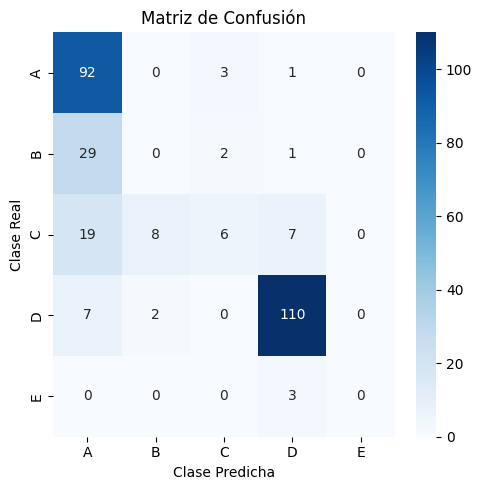

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test_imputed, y_pred_ann)

# Visualizar
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['A', 'B', 'C', 'D', 'E'],
            yticklabels=['A', 'B', 'C', 'D', 'E'])

plt.title('Matriz de Confusión')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.tight_layout()
plt.show()